Number of samples: 1000


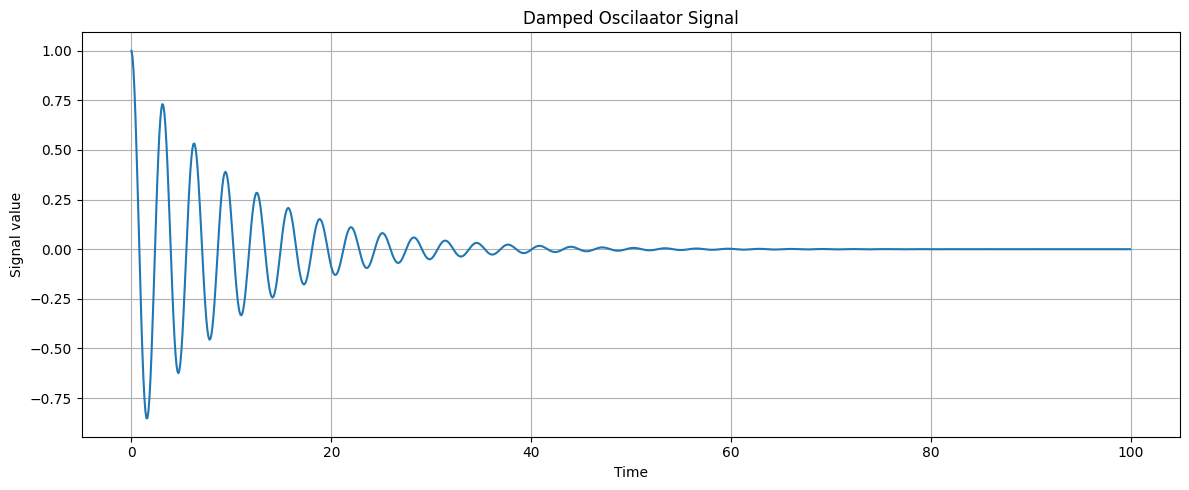

Input shape: (995, 5)
Target shape: (995,)
Training examples: 595
Development examples: 200
Final test examples: 200
Development MAE - Linear Regression: 6.9237066031629585e-18
Development MAE - persistence: 0.00014041432353623822
           Method  Development Test MAE  Final Test MAE
      Persistence          1.837727e-05    1.837727e-05
Linear Regression          1.632615e-18    1.632615e-18
RESULTS INTERPRETATION
Development MAE - Persistence:       1.40414324e-04
Development MAE - Linear Regression: 6.92370660e-18

Final Test MAE - Persistence:       1.83772712e-05
Final Test MAE - Linear Regression: 1.63261524e-18

Relative MAE improvement: 100.0000%

Development result: Linear regression has lower MAE.
Final test result: Linear regression has lower MAE.
Conclusion: Linear regression predicts more accurately on this final test segment.

Numerical note: Linear regression error is extremely small relative to the signal scale.
This is consistent with the deterministic damped oscill

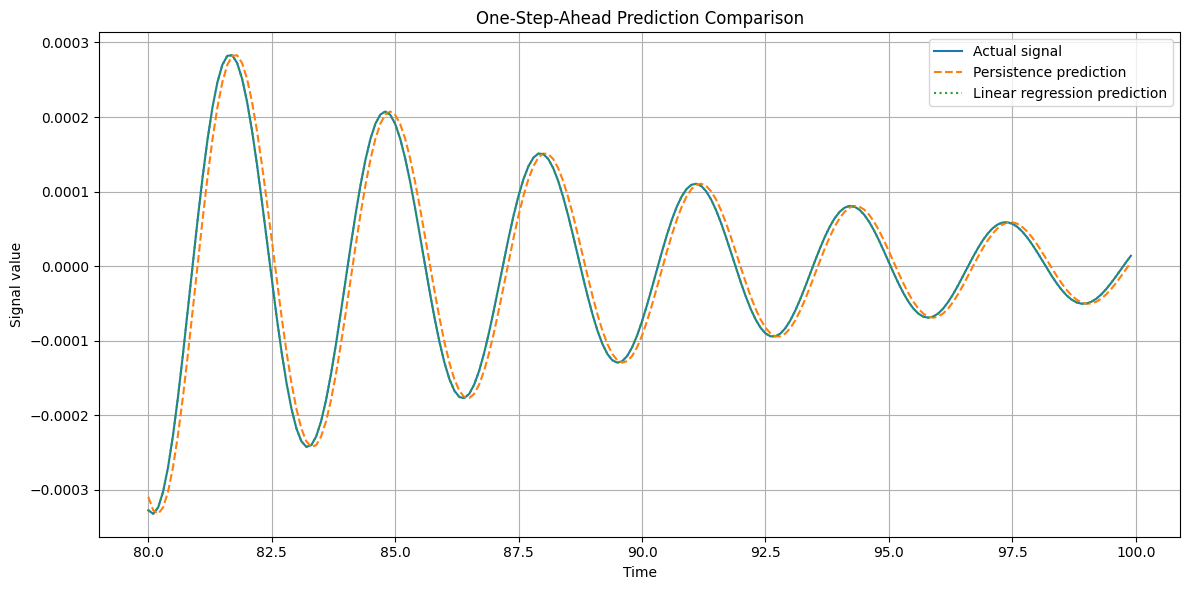

In [13]:
# Import all Libararies

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

# Generate the signal

dt = 0.1
duration = 100.0
t = np.arange(0, duration, dt)
x = np.exp(-0.1*t)*np.cos(2*t)
print("Number of samples:", len(x))

# Visualize the signal

plt.figure(figsize=(12,5))
plt.plot(t, x)
plt.xlabel("Time")
plt.ylabel("Signal value")
plt.title("Damped Oscilaator Signal")
plt.grid(True)
plt.tight_layout()
plt.show()

# Creating the sliding window dataset

window_size = 5
X = []
y = []
target_indices = []
for i in range(window_size, len(x)):
  X.append(x[i - window_size:i])
  y.append(x[i])
  target_indices.append(i)
X = np.asarray(X)
y = np.asarray(y)
target_indices = np.asarray(target_indices)
print("Input shape:", X.shape)
print("Target shape:", y.shape)

# Split data Chornologically

n_samples = len(x)
train_end = int(0.60*n_samples)
dev_end = int(0.80*n_samples)
train_mask = target_indices < train_end

dev_mask = (
    (target_indices >= train_end)
    & (target_indices < dev_end)
)

test_mask = target_indices >= dev_end

X_train, y_train = X[train_mask], y[train_mask]
X_dev, y_dev = X[dev_mask], y[dev_mask]
X_test, y_test = X[test_mask], y[test_mask]
print("Training examples:", len(X_train))
print("Development examples:", len(X_dev))
print("Final test examples:", len(X_test))

# Train the linear regression model

model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)
model.fit(X_train, y_train)

#implement the persistance baseline

pred_dev_linear = model.predict(X_dev)
pred_dev_persistence = X_dev[:, -1]

mae_dev_linear = mean_absolute_error(
    y_dev,
    pred_dev_linear)
mae_dev_persistence = mean_absolute_error(
    y_dev,
    pred_dev_persistence

)
print("Development MAE - Linear Regression:",mae_dev_linear)
print("Development MAE - persistence:",mae_dev_persistence)

# evaluate the final test set

pred_test_linear = model.predict(X_test)

pred_test_persistence = X_test[:, -1]

mae_test_linear = mean_absolute_error(
    y_test,
    pred_test_linear
)

mae_test_persistence = mean_absolute_error(
    y_test,
    pred_test_persistence
)

results = pd.DataFrame({
    "Method": [
        "Persistence",
        "Linear Regression"
    ],
    "Development Test MAE":[
        mae_test_persistence,
        mae_test_linear
    ],
    "Final Test MAE": [
        mae_test_persistence,
        mae_test_linear
    ]
})


print(results.to_string(index=False))

test_t = t[target_indices[test_mask]]


# RESULTS INTERPRETATION

print("=" * 55)
print("RESULTS INTERPRETATION")
print("=" * 55)

# Display the measured results
print(f"Development MAE - Persistence:       {mae_dev_persistence:.8e}")
print(f"Development MAE - Linear Regression: {mae_dev_linear:.8e}")
print()
print(f"Final Test MAE - Persistence:       {mae_test_persistence:.8e}")
print(f"Final Test MAE - Linear Regression: {mae_test_linear:.8e}")
print()

# Calculate percentage improvement on the final test set
if mae_test_persistence > 0:
    improvement = (
        (mae_test_persistence - mae_test_linear)
        / mae_test_persistence
    ) * 100

    print(f"Relative MAE improvement: {improvement:.4f}%")
else:
    improvement = None
    print("Relative improvement is undefined because "
          "persistence MAE is zero.")

print()

# Interpret the development results
if mae_dev_linear < mae_dev_persistence:
    print("Development result: Linear regression has lower MAE.")
elif mae_dev_linear > mae_dev_persistence:
    print("Development result: Persistence has lower MAE.")
else:
    print("Development result: Both methods have equal MAE.")

# Interpret the final test results
if mae_test_linear < mae_test_persistence:
    print("Final test result: Linear regression has lower MAE.")
    print("Conclusion: Linear regression predicts more accurately "
          "on this final test segment.")
elif mae_test_linear > mae_test_persistence:
    print("Final test result: Persistence has lower MAE.")
    print("Conclusion: Linear regression does not improve "
          "on the persistence baseline.")
else:
    print("Final test result: Both methods have equal MAE.")

# Flag numerical precision
signal_scale = np.max(np.abs(y_test))

if signal_scale > 0 and mae_test_linear / signal_scale < 1e-12:
    print()
    print("Numerical note: Linear regression error is extremely "
          "small relative to the signal scale.")
    print("This is consistent with the deterministic damped "
          "oscillator, but verify the implementation and "
          "data separation before reporting the result.")

print()
print("Interpretation complete.")

# plot the results

plt.figure(figsize=(12, 6))

plt.plot(
    test_t,
    y_test,
    label="Actual signal"
)

plt.plot(
    test_t,
    pred_test_persistence,
    label="Persistence prediction",
    linestyle="--"
)

plt.plot(
    test_t,
    pred_test_linear,
    label="Linear regression prediction",
    linestyle=":"
)

plt.xlabel("Time")
plt.ylabel("Signal value")

plt.title("One-Step-Ahead Prediction Comparison")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("prediction_comparison.png", dpi=150)

plt.show()